<a href="https://colab.research.google.com/github/mauryaswasti8-droid/ibl_bwm_explore/blob/main/ibl_bwm_explore.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q dandi pynwb h5py remfile

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 431.5/431.5 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 15.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.4/4.4 MB 45.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 194.2/194.2 kB 12.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 122.0/122.0 kB 8.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 366.6/366.6 kB 29.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 63.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 86.9/86.9 kB 7.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.1/53.1 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.1/118.1 kB 9.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 284.1/284.1 kB 17.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.6/41.6 MB 26.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.7/1

In [ ]:
from dandi.dandiapi import DandiAPIClient
import pynwb, h5py, remfile

client = DandiAPIClient()
dandiset = client.get_dandiset("000409", "0.260309.1324")
path = "sub-CSH-ZAD-001/sub-CSH-ZAD-001_ses-3e7ae7c0-fe8b-487c-9354-036236fa1010_desc-processed_behavior+ecephys.nwb"
asset = dandiset.get_asset_by_path(path)
url = asset.get_content_url(follow_redirects=1, strip_query=True)

f = h5py.File(remfile.File(url), "r")
io = pynwb.NWBHDF5IO(file=f, load_namespaces=True)
nwb = io.read()
print(nwb)

root pynwb.file.NWBFile at 0x136656485034240
Fields:
  devices: {
    Probe00 <class 'pynwb.device.Device'>
  }
  electrode_groups: {
    Probe00 <class 'pynwb.ecephys.ElectrodeGroup'>
  }
  electrodes: electrodes <class 'pynwb.ecephys.ElectrodesTable'>
  file_create_date: [datetime.datetime(2026, 3, 3, 10, 18, 0, 951942, tzinfo=tzlocal())]
  identifier: 15a9c6eb-d2ac-4d49-ac7b-936c1fe3cb39
  institution: Cold Spring Harbor Laboratory
  intervals: {
    trials <class 'pynwb.epoch.TimeIntervals'>
  }
  lab: zadorlab
  lab_meta_data: {
    ibl_metadata <class 'abc.IblMetadata'>,
    ibl_probe_insertion_trajectories <class 'abc.IblProbeInsertionTrajectories'>,
    localization <class 'abc.Localization'>
  }
  processing: {
    lick_times <class 'pynwb.base.ProcessingModule'>,
    wheel <class 'pynwb.base.ProcessingModule'>
  }
  protocol: _iblrig_tasks_ephysChoiceWorld6.2.5
  session_description: 
  session_id: 3e7ae7c0-fe8b-487c-9354-036236fa1010
  session_start_time: 2020-01-16 15:53:21

In [ ]:
print(list(nwb.acquisition.keys()))
print(list(nwb.processing.keys()))
print(list(nwb.intervals.keys()))
print(nwb.units.colnames)

[]
['lick_times', 'wheel']
['trials']
('unit_name', 'electrodes', 'max_electrode', 'max_spike_amplitude_uV', 'probe_name', 'spike_amplitude_std_dB', 'spike_times', 'ibl_quality_score', 'rp_violation', 'spike_amplitudes_uV', 'missed_spikes_estimate', 'firing_rate', 'cluster_uuid', 'waveform_mean', 'cumulative_drift_um_per_hour', 'sliding_rp_violation', 'peak_to_trough_duration_ms', 'kilosort2_label', 'spike_count', 'isi_violations_ratio', 'distance_from_probe_tip_um', 'presence_ratio_std', 'presence_ratio', 'noise_cutoff', 'spike_distances_from_probe_tip_um', 'min_spike_amplitude_uV', 'median_spike_amplitude_uV')


In [ ]:
trials = nwb.intervals["trials"].to_dataframe()
print(trials.columns.tolist())
trials.head()

['start_time', 'stop_time', 'quiescence_period', 'gabor_stimulus_onset_time', 'auditory_cue_time', 'wheel_movement_onset_time', 'choice_registration_time', 'feedback_time', 'gabor_stimulus_offset_time', 'gabor_stimulus_contrast', 'gabor_stimulus_side', 'mouse_wheel_choice', 'is_mouse_rewarded', 'reward_volume_uL', 'probability_left', 'block_type', 'block_index']


,start_time,stop_time,quiescence_period,gabor_stimulus_onset_time,auditory_cue_time,wheel_movement_onset_time,choice_registration_time,feedback_time,gabor_stimulus_offset_time,gabor_stimulus_contrast,gabor_stimulus_side,mouse_wheel_choice,is_mouse_rewarded,reward_volume_uL,probability_left,block_type,block_index
id,,,,,,,,,,,,,,,,,
0,89.422024,92.274432,0.545003,90.157550,90.068459,90.50599,90.701327,90.701429,91.774322,25.00,right,counter_clockwise,True,1.5,0.5,unbiased,0
1,92.666332,96.874214,0.467914,94.773188,94.774055,94.87999,95.307320,95.307402,96.374128,100.00,left,clockwise,True,1.5,0.5,unbiased,0
2,97.222010,101.707428,0.615546,99.789720,99.790687,99.89699,100.138420,100.138518,101.207345,100.00,left,clockwise,True,1.5,0.5,unbiased,0
3,102.055827,105.739622,0.604984,103.806118,103.806952,103.95599,104.184523,104.184614,105.239542,100.00,right,counter_clockwise,True,1.5,0.5,unbiased,0
4,106.131419,110.322831,0.654852,107.324000,107.324900,107.22799,107.767323,107.767889,109.822783,6.25,right,clockwise,False,0.0,0.5,unbiased,0


In [ ]:
print(len(trials))
print(trials["block_type"].value_counts())
print(trials.groupby("block_index")["probability_left"].agg(["first", "count"]))
print(trials["mouse_wheel_choice"].value_counts(dropna=False))

854
block_type
left_block     401
right_block    363
unbiased        90
Name: count, dtype: int64
             first  count
block_index              
0              0.5     90
1              0.2     51
2              0.8     66
3              0.2     49
4              0.8     38
5              0.2     61
6              0.8     62
7              0.2     27
8              0.8     71
9              0.2     99
10             0.8     65
11             0.2     47
12             0.8     96
13             0.2     29
14             0.8      3
mouse_wheel_choice
clockwise            473
counter_clockwise    377
none                   4
Name: count, dtype: int64


In [ ]:
print(nwb.electrodes.colnames)
el = nwb.electrodes.to_dataframe()
el.head()

('location', 'group', 'electrode_name', 'contact_shapes', 'channel_name', 'rel_x', 'rel_y', 'probe_name', 'contact_ids', 'shank_ids', 'adc_group', 'adc_sample_order', 'group_name', 'x', 'y', 'z', 'imp', 'filtering')


,location,group,electrode_name,contact_shapes,channel_name,rel_x,rel_y,probe_name,contact_ids,shank_ids,adc_group,adc_sample_order,group_name,x,y,z,imp,filtering
id,,,,,,,,,,,,,,,,,,
0,void,Probe00 pynwb.ecephys.ElectrodeGroup at 0x1366...,e0,square,"AP0,LF0",16.0,0.0,Probe00,e0,,0,0,Probe00,8050.0,6182.0,4363.0,NaN,
1,void,Probe00 pynwb.ecephys.ElectrodeGroup at 0x1366...,e1,square,"AP1,LF1",48.0,0.0,Probe00,e1,,1,0,Probe00,8050.0,6182.0,4363.0,NaN,
2,void,Probe00 pynwb.ecephys.ElectrodeGroup at 0x1366...,e2,square,"AP2,LF2",0.0,20.0,Probe00,e2,,0,1,Probe00,8050.0,6165.0,4373.0,NaN,
3,void,Probe00 pynwb.ecephys.ElectrodeGroup at 0x1366...,e3,square,"AP3,LF3",32.0,20.0,Probe00,e3,,1,1,Probe00,8050.0,6165.0,4373.0,NaN,
4,root,Probe00 pynwb.ecephys.ElectrodeGroup at 0x1366...,e4,square,"AP4,LF4",16.0,40.0,Probe00,e4,,0,2,Probe00,8050.0,6149.0,4384.0,NaN,


In [ ]:
units = nwb.units.to_dataframe()
print(len(units))
units[["max_electrode", "ibl_quality_score", "firing_rate", "spike_count"]].head()

519


,max_electrode,ibl_quality_score,firing_rate,spike_count
id,,,,
0,location ...,0.666667,15.406116,83465
1,location ...,0.333333,5.631774,30511
2,location ...,0.000000,15.779709,85489
3,location ...,0.333333,17.335734,93919
4,location ...,0.000000,13.176184,71384


In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt

df = trials.copy()
df = df[df["mouse_wheel_choice"].isin(["clockwise", "counter_clockwise"])]

# sanity check: on rewarded trials, side and choice should line up perfectly
print(pd.crosstab(df.loc[df.is_mouse_rewarded == True, "gabor_stimulus_side"],
                  df.loc[df.is_mouse_rewarded == True, "mouse_wheel_choice"]))

mouse_wheel_choice   clockwise  counter_clockwise
gabor_stimulus_side                              
left                       410                  0
right                        0                336


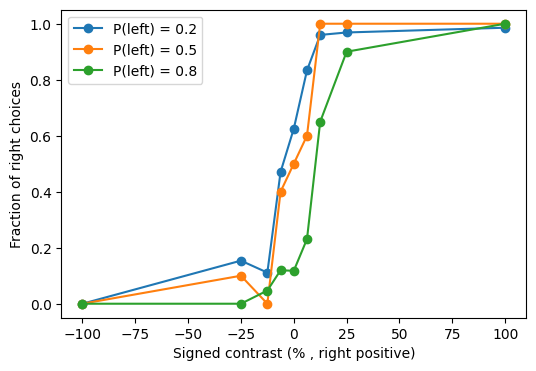

In [ ]:
df["signed_contrast"] = np.where(df["gabor_stimulus_side"] == "left", -1, 1) * df["gabor_stimulus_contrast"]
df["chose_right"] = (df["mouse_wheel_choice"] == "counter_clockwise").astype(int)

plt.figure(figsize=(6, 4))
for p, g in df.groupby("probability_left"):
    curve = g.groupby("signed_contrast")["chose_right"].mean()
    plt.plot(curve.index, curve.values, marker="o", label=f"P(left) = {p}")
plt.xlabel("Signed contrast (% , right positive)")
plt.ylabel("Fraction of right choices")
plt.legend()
plt.show()

In [ ]:
counts = df.groupby(["probability_left", "signed_contrast"]).size().unstack(0)
print(counts)

probability_left  0.2  0.5  0.8
signed_contrast                
-100.00            21   10   63
-25.00             13   10   75
-12.50             18   10   85
-6.25              17   10   67
 0.00              40   10   51
 6.25              66   10   13
 12.50             50   10   20
 25.00             64   10   10
 100.00            70   10   17


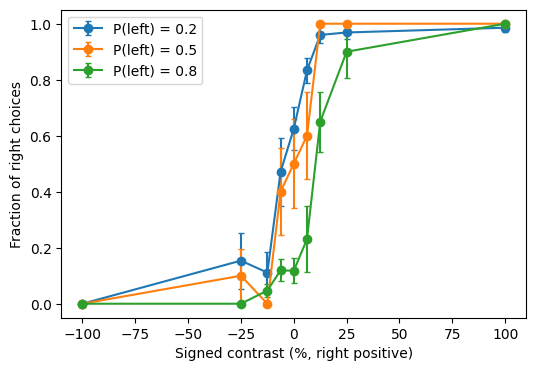

In [ ]:
plt.figure(figsize=(6, 4))
for p, g in df.groupby("probability_left"):
    s = g.groupby("signed_contrast")["chose_right"].agg(["mean", "count"])
    se = np.sqrt(s["mean"] * (1 - s["mean"]) / s["count"])
    plt.errorbar(s.index, s["mean"], yerr=se, marker="o", capsize=2, label=f"P(left) = {p}")
plt.xlabel("Signed contrast (%, right positive)")
plt.ylabel("Fraction of right choices")
plt.legend()
plt.show()

In [ ]:
print(type(units["max_electrode"].iloc[0]))

<class 'pandas.core.frame.DataFrame'>


In [ ]:
units["region"] = units["max_electrode"].apply(lambda x: x["location"].iloc[0])
print(units["region"].value_counts())

good = units[units["ibl_quality_score"] >= 0.99]
print(len(good))
print(good["region"].value_counts())

region
Midbrain                                        225
Precommissural nucleus                           53
Midbrain reticular nucleus                       47
Fields of Forel                                  37
Substantia nigra reticular part                  28
cerebal peduncle                                 27
Ventral tegmental area                           25
Subparafascicular nucleus parvicellular part     20
Substantia nigra compact part                    18
root                                             16
posterior commissure                              7
void                                              5
choroid plexus                                    4
Thalamus                                          3
habenular commissure                              3
third ventricle                                   1
Name: count, dtype: int64
50
region
Midbrain                                        18
Fields of Forel                                  6
Substantia nigra reticu

In [ ]:
good = units[units["ibl_quality_score"] >= 0.99].copy()

tr = trials.copy()
tr = tr[tr["gabor_stimulus_onset_time"].notna()]
tr = tr[tr["probability_left"] != 0.5]          # drop the unbiased block
tr = tr[tr["block_index"] != tr["block_index"].max()]  # drop the 3-trial last block

t0 = tr["gabor_stimulus_onset_time"].values
win = (-0.6, -0.1)  # seconds relative to stimulus onset

X = np.array([[np.sum((st >= t + win[0]) & (st < t + win[1])) for st in good["spike_times"]]
              for t in t0])
y = (tr["probability_left"].values == 0.8).astype(int)
groups = tr["block_index"].values
print(X.shape, y.mean())

(761, 50) 0.5229960578186597


In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold, cross_val_score

clf = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=2000))
scores = cross_val_score(clf, X, y, groups=groups, cv=GroupKFold(n_splits=5))
print(scores, scores.mean(), "majority baseline:", max(y.mean(), 1 - y.mean()))

[0.15753425 0.3862069  0.25       0.22435897 0.64285714] 0.33219145206863676 majority baseline: 0.5229960578186597


In [ ]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import balanced_accuracy_score, roc_auc_score

clf = make_pipeline(StandardScaler(),
                    LogisticRegression(C=0.1, max_iter=2000, class_weight="balanced"))
cv = GroupKFold(n_splits=5)

# class mix of each test fold, to see the imbalance directly
for i, (tr_i, te_i) in enumerate(cv.split(X, y, groups)):
    print(i, "test frac class 1:", round(y[te_i].mean(), 2), "n =", len(te_i))

proba = cross_val_predict(clf, X, y, groups=groups, cv=cv, method="predict_proba")[:, 1]
print("balanced acc:", balanced_accuracy_score(y, proba > 0.5))
print("AUC:", roc_auc_score(y, proba))

0 test frac class 1: 0.0 n = 146
1 test frac class 1: 0.66 n = 145
2 test frac class 1: 0.68 n = 160
3 test frac class 1: 0.42 n = 156
4 test frac class 1: 0.82 n = 154
balanced acc: 0.37520938023450584
AUC: 0.3005108185555878


In [ ]:
from sklearn.model_selection import PredefinedSplit, cross_val_predict
from sklearn.metrics import roc_auc_score

def pseudo_blocks(n_trials, rng):
    labels = [0.5] * 90
    side = rng.choice([0.2, 0.8])
    while len(labels) < n_trials:
        L = int(rng.exponential(60))
        while not (20 <= L <= 100):
            L = int(rng.exponential(60))
        labels += [side] * L
        side = 0.8 if side == 0.2 else 0.2
    return np.array(labels[:n_trials])

def decode_auc(X, y):
    folds = np.arange(len(y)) % 5   # interleaved folds
    clf = make_pipeline(StandardScaler(),
                        LogisticRegression(penalty="l1", solver="liblinear", C=0.1))
    p = cross_val_predict(clf, X, y, cv=PredefinedSplit(folds), method="predict_proba")[:, 1]
    return roc_auc_score(y, p)

idx = tr.index.values            # positions of the trials in X
real = decode_auc(X, y)

rng = np.random.default_rng(0)
null = []
for _ in range(200):
    pl = pseudo_blocks(len(trials), rng)[idx]
    yp = (pl == 0.8).astype(int)
    if yp.min() == yp.max():
        continue
    null.append(decode_auc(X, yp))
null = np.array(null)

print("real AUC:", round(real, 3))
print("null median:", np.median(null).round(3), "| 95th percentile:", np.percentile(null, 95).round(3))
print("p ~", (np.sum(null >= real) + 1) / (len(null) + 1))

real AUC: 0.754
null median: 0.653 | 95th percentile: 0.722
p ~ 0.004975124378109453


In [2]:
!pip install -q dandi pynwb h5py remfile

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 431.5/431.5 kB 16.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 51.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.4/4.4 MB 77.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 194.2/194.2 kB 11.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 122.0/122.0 kB 7.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 366.6/366.6 kB 19.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 52.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 86.9/86.9 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.1/53.1 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.1/118.1 kB 5.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 284.1/284.1 kB 15.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.6/41.6 MB 24.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.7/

In [3]:
import numpy as np, pandas as pd
from dandi.dandiapi import DandiAPIClient
import pynwb, h5py, remfile
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import PredefinedSplit, cross_val_predict
from sklearn.metrics import roc_auc_score

# --- load the session ---
client = DandiAPIClient()
dandiset = client.get_dandiset("000409", "0.260309.1324")
path = "sub-CSH-ZAD-001/sub-CSH-ZAD-001_ses-3e7ae7c0-fe8b-487c-9354-036236fa1010_desc-processed_behavior+ecephys.nwb"
asset = dandiset.get_asset_by_path(path)
url = asset.get_content_url(follow_redirects=1, strip_query=True)
f = h5py.File(remfile.File(url), "r")
nwb = pynwb.NWBHDF5IO(file=f, load_namespaces=True).read()

trials = nwb.intervals["trials"].to_dataframe()
units = nwb.units.to_dataframe()

# --- rebuild the decoding inputs (same choices as before) ---
good = units[units["ibl_quality_score"] >= 0.99].copy()
tr = trials.copy()
tr = tr[tr["gabor_stimulus_onset_time"].notna()]
tr = tr[tr["probability_left"] != 0.5]
tr = tr[tr["block_index"] != tr["block_index"].max()]

t0 = tr["gabor_stimulus_onset_time"].values
win = (-0.6, -0.1)
X = np.array([[np.sum((st >= t + win[0]) & (st < t + win[1])) for st in good["spike_times"]]
              for t in t0])
y = (tr["probability_left"].values == 0.8).astype(int)
idx = tr.index.values
print(X.shape, y.mean())

(761, 50) 0.5229960578186597


In [4]:
# --- the pseudosession tools from last time ---
def pseudo_blocks(n_trials, rng):
    labels = [0.5] * 90
    side = rng.choice([0.2, 0.8])
    while len(labels) < n_trials:
        L = int(rng.exponential(60))
        while not (20 <= L <= 100):
            L = int(rng.exponential(60))
        labels += [side] * L
        side = 0.8 if side == 0.2 else 0.2
    return np.array(labels[:n_trials])

def decode_auc(X, y):
    folds = np.arange(len(y)) % 5
    clf = make_pipeline(StandardScaler(),
                        LogisticRegression(penalty="l1", solver="liblinear", C=0.1))
    p = cross_val_predict(clf, X, y, cv=PredefinedSplit(folds), method="predict_proba")[:, 1]
    return roc_auc_score(y, p)

print("real AUC:", round(decode_auc(X, y), 3))   # should print 0.754 again

real AUC: 0.754


In [5]:
np.savez("pilot_session.npz", X=X, y=y, idx=idx)
trials.to_csv("pilot_trials.csv")

In [6]:
full = trials.copy()
full["prev_choice"]   = (full["mouse_wheel_choice"].shift(1) == "counter_clockwise").astype(float)
full["prev_rewarded"] = full["is_mouse_rewarded"].shift(1).fillna(0).astype(float)
full["prev_side"]     = (full["gabor_stimulus_side"].shift(1) == "right").astype(float)

# exponentially weighted average of past choices (decay ~5.45 trials, from the paper)
a = (full["mouse_wheel_choice"] == "counter_clockwise").astype(float).values
alpha, k = 1/5.45, np.full(len(a), 0.5)
for t in range(1, len(a)):
    k[t] = (1 - alpha) * k[t-1] + alpha * a[t-1]
full["choice_kernel"] = k

H  = full.loc[idx, ["prev_choice", "prev_rewarded", "prev_side", "choice_kernel"]].values
XH = np.hstack([X, H])

def null_dist(F, n=200, seed=1):
    rng, out = np.random.default_rng(seed), []
    for _ in range(n):
        yp = (pseudo_blocks(len(trials), rng)[idx] == 0.8).astype(int)
        if yp.min() != yp.max():
            out.append(decode_auc(F, yp))
    return np.array(out)

for name, F in [("history only", H), ("neural only", X), ("neural + history", XH)]:
    r, nl = decode_auc(F, y), null_dist(F)
    print(f"{name:18s} AUC {r:.3f} | null median {np.median(nl):.3f} | 95th pct {np.percentile(nl,95):.3f}")

history only       AUC 0.948 | null median 0.574 | 95th pct 0.727
neural only        AUC 0.754 | null median 0.651 | 95th pct 0.714
neural + history   AUC 0.952 | null median 0.673 | 95th pct 0.764


In [7]:
from sklearn.linear_model import LinearRegression

Xr = X - LinearRegression().fit(H, X).predict(H)   # neural counts with linear history removed
r, nl = decode_auc(Xr, y), null_dist(Xr)
print(f"neural residual    AUC {r:.3f} | null median {np.median(nl):.3f} | 95th pct {np.percentile(nl,95):.3f}")

neural residual    AUC 0.479 | null median 0.637 | 95th pct 0.703
